<a href="https://colab.research.google.com/github/Harsh6465/ShadowFox_Task/blob/main/TASK2_Shadowfox.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [ ]:
# Load dataset
df = pd.read_csv(
    "/kaggle/input/datasets/harshchopda24/city-day/city_day.csv"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset Shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [ ]:

print("Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

df.describe()


Columns:
['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-nul

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI
count,24933.000000,18391.000000,25949.000000,25946.000000,25346.000000,19203.000000,27472.000000,25677.000000,25509.000000,23908.000000,21490.000000,11422.000000,24850.000000
mean,67.450578,118.127103,17.574730,28.560659,32.309123,23.483476,2.248598,14.531977,34.491430,3.280840,8.700972,3.070128,166.463581
std,64.661449,90.605110,22.785846,24.474746,31.646011,25.684275,6.962884,18.133775,21.694928,15.811136,19.969164,6.323247,140.696585
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000,0.000000,0.000000,0.000000,13.000000
25%,28.820000,56.255000,5.630000,11.750000,12.820000,8.580000,0.510000,5.670000,18.860000,0.120000,0.600000,0.140000,81.000000
50%,48.570000,95.680000,9.890000,21.690000,23.520000,15.850000,0.890000,9.160000,30.840000,1.070000,2.970000,0.980000,118.000000
75%,80.590000,149.745000,19.950000,37.620000,40.127500,30.020000,1.450000,15.220000,45.570000,3.080000,9.150000,3.350000,208.000000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000,455.030000,454.850000,170.370000,2049.000000


In [ ]:


df_delhi = df[
    df["City"].astype(str).str.strip().str.lower() == "delhi"
].copy()

print("Delhi AQI Dataset Shape:", df_delhi.shape)

df_delhi.head()


Delhi AQI Dataset Shape: (2009, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
10229,Delhi,2015-01-01,313.22,607.98,69.16,36.39,110.59,33.85,15.20,9.25,41.68,14.36,24.86,9.84,472.0,Severe
10230,Delhi,2015-01-02,186.18,269.55,62.09,32.87,88.14,31.83,9.54,6.65,29.97,10.55,20.09,4.29,454.0,Severe
10231,Delhi,2015-01-03,87.18,131.90,25.73,30.31,47.95,69.55,10.61,2.65,19.71,3.91,10.23,1.99,143.0,Moderate
10232,Delhi,2015-01-04,151.84,241.84,25.01,36.91,48.62,130.36,11.54,4.63,25.36,4.26,9.71,3.34,319.0,Very Poor
10233,Delhi,2015-01-05,146.60,219.13,14.01,34.92,38.25,122.88,9.20,3.33,23.20,2.80,6.21,2.96,325.0,Very Poor


In [ ]:

# Convert Date column into datetime format
df_delhi["Date"] = pd.to_datetime(
    df_delhi["Date"], errors="coerce"
)

# Display dataset information
print("Delhi Dataset Information:")
df_delhi.info()

# Check missing values
print("\nMissing Values in Delhi Dataset:")
print(df_delhi.isnull().sum())

# Statistical summary of AQI
print("\nAQI Statistical Summary:")
print(df_delhi["AQI"].describe())


Delhi Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 2009 entries, 10229 to 12237
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        2009 non-null   object        
 1   Date        2009 non-null   datetime64[ns]
 2   PM2.5       2007 non-null   float64       
 3   PM10        1932 non-null   float64       
 4   NO          2007 non-null   float64       
 5   NO2         2007 non-null   float64       
 6   NOx         2009 non-null   float64       
 7   NH3         2000 non-null   float64       
 8   CO          2009 non-null   float64       
 9   SO2         1899 non-null   float64       
 10  O3          1925 non-null   float64       
 11  Benzene     2009 non-null   float64       
 12  Toluene     2009 non-null   float64       
 13  Xylene      1228 non-null   float64       
 14  AQI         1999 non-null   float64       
 15  AQI_Bucket  1999 non-null   object        
dt

In [ ]:

# Count records in each AQI category
print("AQI Category Distribution:")

print(df_delhi["AQI_Bucket"].value_counts())

# Display unique AQI categories
print("\nAvailable AQI Categories:")
print(df_delhi["AQI_Bucket"].unique())


AQI Category Distribution:
AQI_Bucket
Poor            542
Very Poor       520
Moderate        519
Severe          239
Satisfactory    158
Good             21
Name: count, dtype: int64

Available AQI Categories:
['Severe' 'Moderate' 'Very Poor' 'Poor' 'Satisfactory' nan 'Good']


**Data Cleaning and Preprocessing**

Data cleaning is the process of identifying and handling missing values, incorrect data types and duplicate records. It improves data quality and helps produce more reliable analysis results.

In [ ]:


df_clean = df_delhi.copy()

# Convert Date and AQI into proper formats
df_clean["Date"] = pd.to_datetime(df_clean["Date"], errors="coerce")
df_clean["AQI"] = pd.to_numeric(df_clean["AQI"], errors="coerce")


print("Missing values before cleaning:")
print(df_clean.isnull().sum())

df_clean = df_clean.dropna(subset=["Date", "AQI"])

df_clean = df_clean.drop_duplicates()

df_clean.reset_index(drop=True, inplace=True)

print("\nShape of cleaned dataset:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean[["Date", "AQI"]].isnull().sum())

print("\nFirst 5 records:")
display(df_clean.head())

Missing values before cleaning:
City            0
Date            0
PM2.5           2
PM10           77
NO              2
NO2             2
NOx             0
NH3             9
CO              0
SO2           110
O3             84
Benzene         0
Toluene         0
Xylene        781
AQI            10
AQI_Bucket     10
dtype: int64

Shape of cleaned dataset: (1999, 16)

Missing values after cleaning:
Date    0
AQI     0
dtype: int64

First 5 records:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Delhi,2015-01-01,313.22,607.98,69.16,36.39,110.59,33.85,15.20,9.25,41.68,14.36,24.86,9.84,472.0,Severe
1,Delhi,2015-01-02,186.18,269.55,62.09,32.87,88.14,31.83,9.54,6.65,29.97,10.55,20.09,4.29,454.0,Severe
2,Delhi,2015-01-03,87.18,131.90,25.73,30.31,47.95,69.55,10.61,2.65,19.71,3.91,10.23,1.99,143.0,Moderate
3,Delhi,2015-01-04,151.84,241.84,25.01,36.91,48.62,130.36,11.54,4.63,25.36,4.26,9.71,3.34,319.0,Very Poor
4,Delhi,2015-01-05,146.60,219.13,14.01,34.92,38.25,122.88,9.20,3.33,23.20,2.80,6.21,2.96,325.0,Very Poor


In [ ]:

print("Final AQI Statistics")

print("Average AQI:", round(df_clean["AQI"].mean(), 2))
print("Maximum AQI:", df_clean["AQI"].max())
print("Minimum AQI:", df_clean["AQI"].min())
print("Median AQI:", df_clean["AQI"].median())


Final AQI Statistics
Average AQI: 259.49
Maximum AQI: 716.0
Minimum AQI: 29.0
Median AQI: 257.0


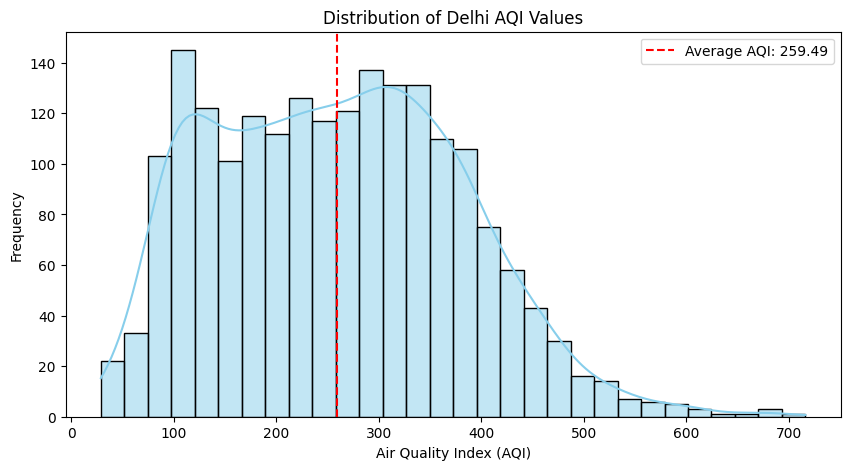

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="AQI",
    bins=30,
    kde=True,
    color="skyblue"
)


mean_aqi = df_clean["AQI"].mean()

plt.axvline(
    mean_aqi,
    color="red",
    linestyle="--",
    label=f"Average AQI: {mean_aqi:.2f}"
)

# Add title and labels
plt.title("Distribution of Delhi AQI Values")
plt.xlabel("Air Quality Index (AQI)")
plt.ylabel("Frequency")

plt.legend()
plt.show()


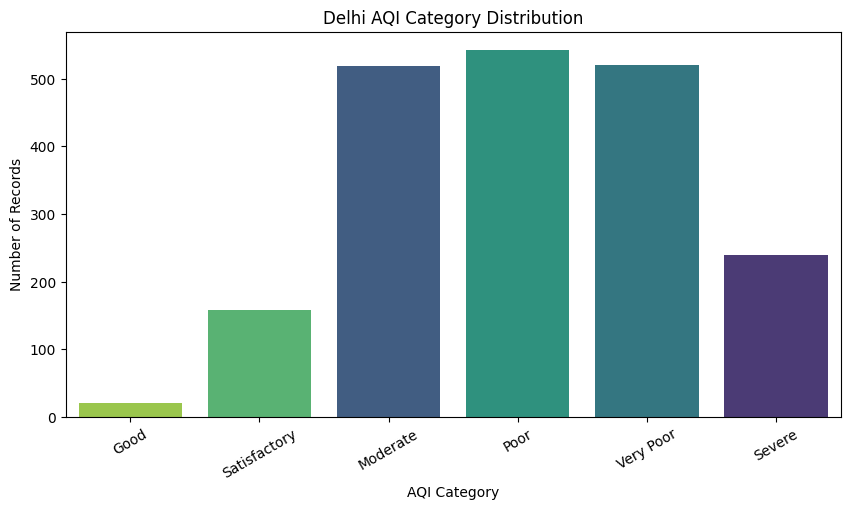

In [ ]:

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="AQI_Bucket",
    order=[
        "Good",
        "Satisfactory",
        "Moderate",
        "Poor",
        "Very Poor",
        "Severe"
    ],
    hue="AQI_Bucket",
    palette="viridis",
    legend=False
)

plt.title("Delhi AQI Category Distribution")
plt.xlabel("AQI Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)

plt.show()


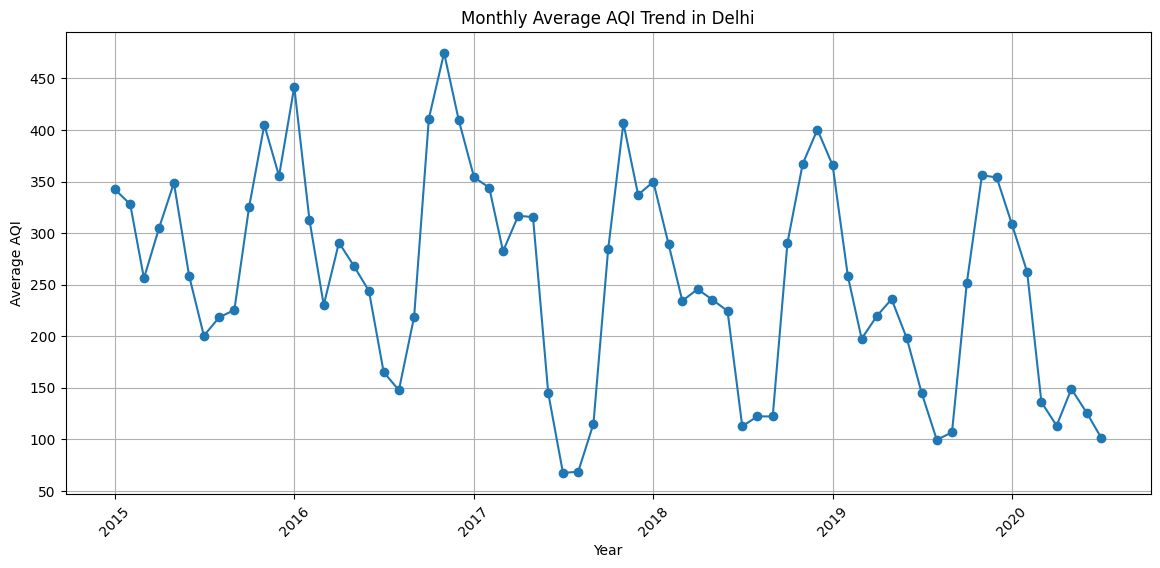

In [ ]:

# Convert Date column into datetime format
df_clean["Date"] = pd.to_datetime(df_clean["Date"])

# Calculate monthly average AQI
monthly_aqi = df_clean.set_index("Date")["AQI"].resample("MS").mean()

# Remove empty values
monthly_aqi = monthly_aqi.dropna()

# Plot monthly AQI trend
plt.figure(figsize=(14, 6))

plt.plot(monthly_aqi.index, monthly_aqi.values, marker="o")

# Add graph title and labels
plt.title("Monthly Average AQI Trend in Delhi")
plt.xlabel("Year")
plt.ylabel("Average AQI")

# Improve graph appearance
plt.xticks(rotation=45)
plt.grid(True)

plt.show()


**Description:**

PM2.5 and PM10 are major air pollutants that affect air quality and human health.
- PM2.5: Fine particles with a diameter of 2.5 micrometers or smaller.
- PM10: Particles with a diameter of 10 micrometers or smaller.


**Objectives:**

- Analyze PM2.5 and PM10 pollution levels.
- Compare their average concentrations.
- Identify monthly pollution patterns.
- Understand changes in particulate pollution over time.

In [ ]:


print("PM2.5 Statistics:")
print(df_clean["PM2.5"].describe())


print(df_clean["PM10"].describe())

print("\nAverage PM2.5:", round(df_clean["PM2.5"].mean(), 2))
print("Average PM10:", round(df_clean["PM10"].mean(), 2))

PM2.5 Statistics:
count    1998.000000
mean      117.549770
std        82.925457
min        10.240000
25%        57.272500
50%        94.980000
75%       153.317500
max       685.360000
Name: PM2.5, dtype: float64
count    1930.000000
mean      232.902974
std       121.899996
min        18.590000
25%       137.157500
50%       217.015000
75%       311.842500
max       796.880000
Name: PM10, dtype: float64

Average PM2.5: 117.55
Average PM10: 232.9


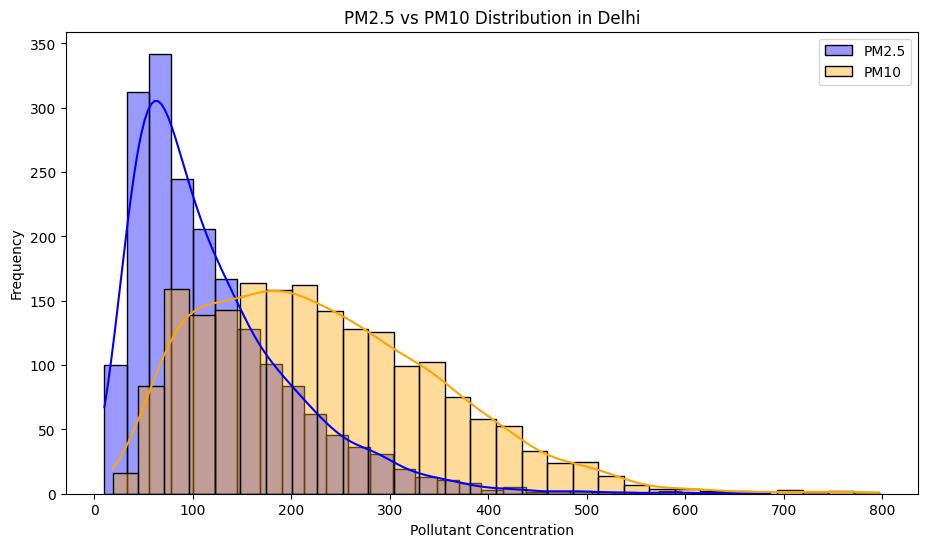

In [ ]:


pollution_data = df_clean[["PM2.5", "PM10"]].dropna()


plt.figure(figsize=(11, 6))


sns.histplot(pollution_data["PM2.5"], bins=30, kde=True,
             color="blue", label="PM2.5", alpha=0.4)


sns.histplot(pollution_data["PM10"], bins=30, kde=True,
             color="orange", label="PM10", alpha=0.4)


plt.title("PM2.5 vs PM10 Distribution in Delhi")
plt.xlabel("Pollutant Concentration")
plt.ylabel("Frequency")

plt.legend()
plt.show()


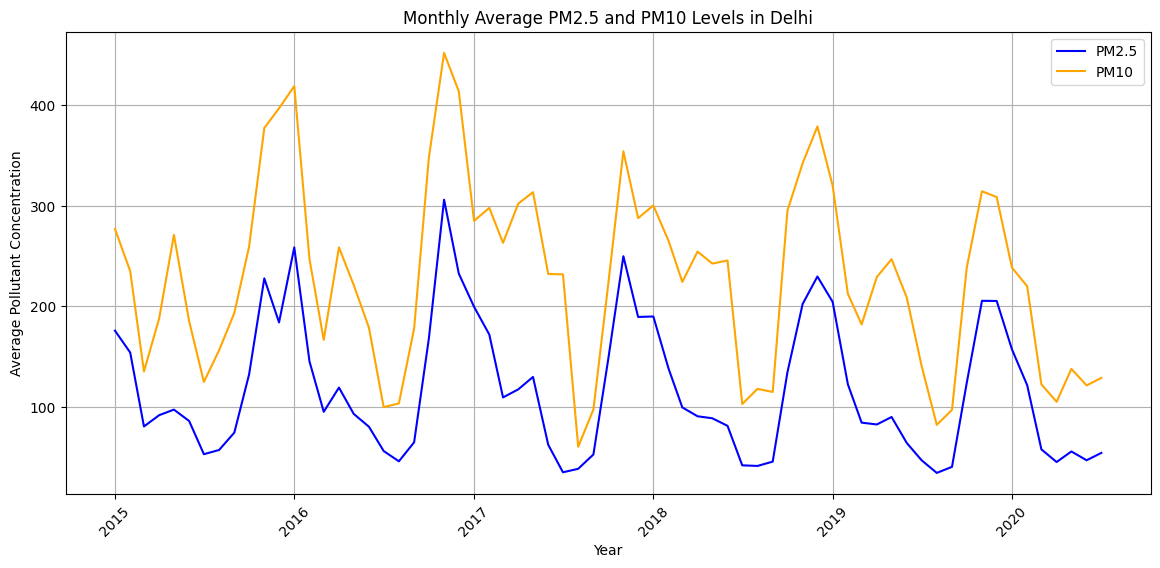

In [ ]:

# Calculate monthly average PM2.5 and PM10
monthly_pollution = df_clean.set_index("Date")[["PM2.5", "PM10"]].resample("MS").mean()

# Create line graph
plt.figure(figsize=(14, 6))

# Plot PM2.5
plt.plot(monthly_pollution.index, monthly_pollution["PM2.5"],
         label="PM2.5", color="blue")

# Plot PM10
plt.plot(monthly_pollution.index, monthly_pollution["PM10"],
         label="PM10", color="orange")

# Add title and labels
plt.title("Monthly Average PM2.5 and PM10 Levels in Delhi")
plt.xlabel("Year")
plt.ylabel("Average Pollutant Concentration")

# Display graph details
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.show()


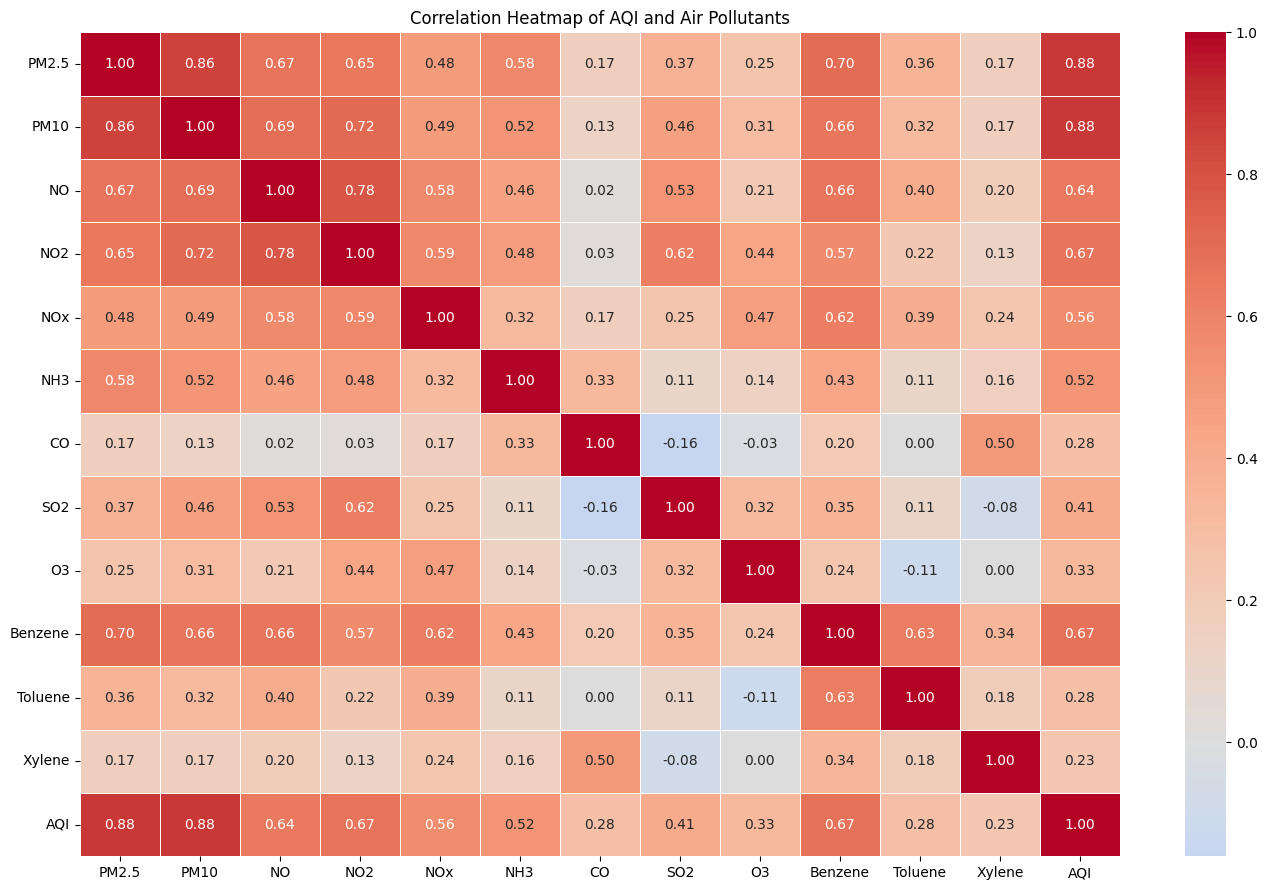

In [ ]:

# Select numerical pollutant columns
pollutants = [
    "PM2.5", "PM10", "NO", "NO2",
    "NOx", "NH3", "CO", "SO2",
    "O3", "Benzene", "Toluene", "Xylene", "AQI"
]

# Calculate correlation matrix
correlation_matrix = df_clean[pollutants].corr()

# Create heatmap
plt.figure(figsize=(14, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

# Add title
plt.title("Correlation Heatmap of AQI and Air Pollutants")

plt.tight_layout()
plt.show()


In [ ]:

print("Delhi AQI Analysis Period:")
print("Start Date:", df_clean["Date"].min().date())
print("End Date:", df_clean["Date"].max().date())

print("\nAverage AQI:", round(df_clean["AQI"].mean(), 2))


print("Maximum AQI:", df_clean["AQI"].max())
print("Minimum AQI:", df_clean["AQI"].min())


print("\nAQI Category Distribution:")
print(df_clean["AQI_Bucket"].value_counts())


pollutants = ["PM2.5", "PM10", "NO2", "CO", "SO2", "O3"]

print("\nAverage Pollutant Levels:")
print(df_clean[pollutants].mean().round(2))


highest_aqi = df_clean.loc[df_clean["AQI"].idxmax()]

print("\nHighest AQI Record:")
print("Date:", highest_aqi["Date"].date())
print("AQI:", highest_aqi["AQI"])
print("Category:", highest_aqi["AQI_Bucket"])


Delhi AQI Analysis Period:
Start Date: 2015-01-01
End Date: 2020-07-01

Average AQI: 259.49
Maximum AQI: 716.0
Minimum AQI: 29.0

AQI Category Distribution:
AQI_Bucket
Poor            542
Very Poor       520
Moderate        519
Severe          239
Satisfactory    158
Good             21
Name: count, dtype: int64

Average Pollutant Levels:
PM2.5    117.55
PM10     232.90
NO2       50.76
CO         1.99
SO2       15.91
O3        51.34
dtype: float64

Highest AQI Record:
Date: 2016-11-07
AQI: 716.0
Category: Severe


In [ ]:

# Save cleaned Delhi dataset
df_clean.to_csv(
    "Delhi_AQI_Cleaned_Dataset.csv",
    index=False
)

print("Cleaned dataset exported successfully!")


Cleaned dataset exported successfully!


**Key Findings:**

1. The average AQI of Delhi during the analyzed period was calculated from the dataset.
2. The most frequently occurring AQI category was identified.
3. The highest and lowest AQI values were observed.
4. PM2.5 and PM10 showed different pollution concentration patterns.
5. The correlation heatmap helped identify relationships between AQI and different pollutants.
6. Monthly analysis helped identify changes in pollution levels over time.

**Recommendations to Reduce Air Pollution:**

1. Promote public transportation and carpooling.
2. Encourage the use of electric vehicles.
3. Control industrial emissions.
4. Reduce construction dust and road dust.
5. Increase tree plantation and green spaces.
6. Monitor air quality regularly.
7. Spread awareness about air pollution and its health effects.

**Conclusion:**

The Delhi AQI Analysis project demonstrates how Python can be used to analyze air pollution data and understand environmental conditions.
Using Pandas, NumPy, Matplotlib and Seaborn, the dataset was explored, cleaned and visualized through different graphs.
The analysis covered AQI distribution, AQI categories, monthly pollution trends, PM2.5 and PM10 levels, and correlations between different pollutants.
This project helped identify important air quality patterns and understand the role of data analysis in environmental monitoring.